# Digital Image Processing Lab 02
**Name:** Sheikh Haseeb-ur-Rehman 
**Roll No:** 2024-SE-31  

Digital Images, Pixels, Color, and Basic Transformations

## Step 1: Virtual Environment Verification
This notebook runs on the `.venv` kernel. The cell below verifies the Python executable, the library imports, and that `.venv/` is listed in `.gitignore`.

In [1]:
import sys
import platform

print("Python executable        :", sys.executable)
print("Python version           :", platform.python_version())
print("Inside a virtual env     :", sys.prefix != sys.base_prefix)

import numpy
import cv2
import matplotlib
print("numpy version            :", numpy.__version__)
print("opencv-python version    :", cv2.__version__)
print("matplotlib version       :", matplotlib.__version__)

with open(".gitignore") as f:
    entries = [line.strip() for line in f if line.strip()]
print(".gitignore entries       :", entries)
print(".venv/ is git-ignored    :", ".venv/" in entries)

Python executable        : c:\Users\HP\OneDrive\Desktop\dip-lab-02\.venv\Scripts\python.exe
Python version           : 3.14.5
Inside a virtual env     : True
numpy version            : 2.5.4
opencv-python version    : 5.0.0
matplotlib version       : 3.11.2
.gitignore entries       : ['.venv/']
.venv/ is git-ignored    : True


## Step 2: Load the Image

In [2]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

IMAGE_NAME = "photo.jpg"

image = cv.imread(IMAGE_NAME)  # OpenCV loads color images in BGR order
if image is None:
    raise FileNotFoundError(f"Image not found or unreadable: {IMAGE_NAME}")

os.makedirs("evidence", exist_ok=True)  # extra figures for the report

print("Image shape     :", image.shape)
print("Image data type :", image.dtype)

Image shape     : (1792, 2400, 3)
Image data type : uint8


## Step 3: Inspect the Image

In [3]:
height, width, channels = image.shape
print("Height (rows)      :", height)
print("Width (columns)    :", width)
print("Number of channels :", channels)

if height < 300 or width < 300:
    raise ValueError("Image must be at least 300 x 300 pixels.")

cy, cx = height // 2, width // 2
# Pixels are indexed [row, column] = [y, x]; OpenCV order is (B, G, R)
print("Top-left pixel [0, 0] (B, G, R)     :", image[0, 0])
print(f"Center pixel [{cy}, {cx}] (B, G, R) :", image[cy, cx])

print("Global minimum value :", image.min())
print("Global maximum value :", image.max())
print("Blue  channel min / max :", image[:, :, 0].min(), "/", image[:, :, 0].max())
print("Green channel min / max :", image[:, :, 1].min(), "/", image[:, :, 1].max())
print("Red   channel min / max :", image[:, :, 2].min(), "/", image[:, :, 2].max())

Height (rows)      : 1792
Width (columns)    : 2400
Number of channels : 3
Top-left pixel [0, 0] (B, G, R)     : [35 23 43]
Center pixel [896, 1200] (B, G, R) : [  4 139 183]
Global minimum value : 0
Global maximum value : 255
Blue  channel min / max : 0 / 255
Green channel min / max : 0 / 255
Red   channel min / max : 0 / 255


## Step 4: Convert Colors and Separate Channels

RGB shape       : (1792, 2400, 3)
Grayscale shape : (1792, 2400)


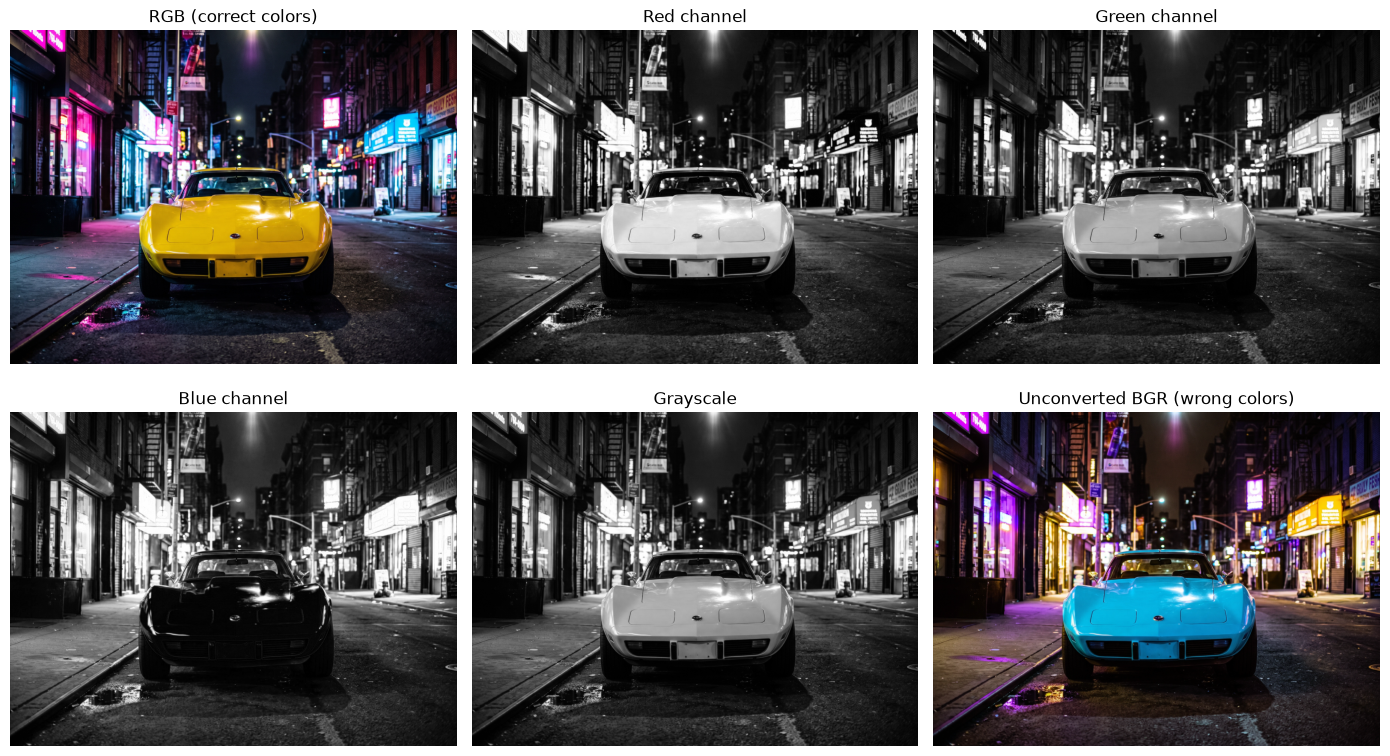

Center pixel RGB : (183, 139, 4)
Center pixel HEX : #B78B04


In [4]:
rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
r, g, b = rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]

print("RGB shape       :", rgb.shape)
print("Grayscale shape :", gray.shape)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
panels = [
    (rgb, "RGB (correct colors)", None),
    (r, "Red channel", "gray"),
    (g, "Green channel", "gray"),
    (b, "Blue channel", "gray"),
    (gray, "Grayscale", "gray"),
    (image, "Unconverted BGR (wrong colors)", None),
]
for ax, (img, title, cmap) in zip(axes.ravel(), panels):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
fig.savefig("evidence/channels_figure.png", dpi=120)
plt.show()

# Center pixel RGB -> HEX
cr, cg, cb = (int(v) for v in rgb[cy, cx])
hex_value = f"#{cr:02X}{cg:02X}{cb:02X}"
print(f"Center pixel RGB : ({cr}, {cg}, {cb})")
print("Center pixel HEX :", hex_value)

**Color and channel analysis:**

- **BGR vs RGB:** OpenCV's `cv.imread()` stores the channels in the order Blue, Green, Red, while Matplotlib's `imshow()` expects Red, Green, Blue. Showing the BGR array directly swaps red and blue, so the yellow car appears blue/cyan in the last panel. Converting with `cv.COLOR_BGR2RGB` fixes this.
- **Channels:** Each channel is a 2-D grayscale image of how much of that color is present at each pixel (brighter = more). The yellow car is bright in the red and green channels and dark in the blue channel, because yellow is red + green with almost no blue. The center pixel confirms this: its OpenCV value is (B, G, R) = (4, 139, 183), which is RGB (183, 139, 4) = `#B78B04`.
- **Grayscale:** The grayscale image is a single-channel weighted combination of the three channels (OpenCV uses roughly 0.299 R + 0.587 G + 0.114 B).

## Step 5: Crop, Resize, and Save

Crop region : rows 846:946, cols 1150:1250
Crop shape  : (100, 100, 3)
Resized shape: (200, 200, 3)


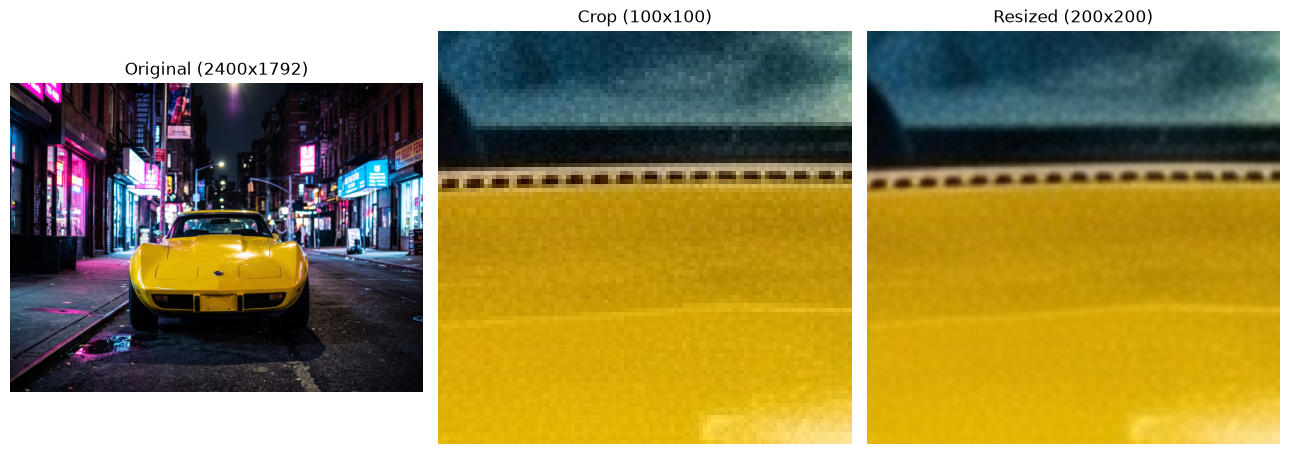

cv.imwrite() saved resized_crop.png successfully: True


In [5]:
# Exact 100 x 100 crop centered on the image: image[y_start:y_end, x_start:x_end]
y_start, y_end = cy - 50, cy + 50
x_start, x_end = cx - 50, cx + 50
crop = rgb[y_start:y_end, x_start:x_end]   # crop the RGB copy so Matplotlib shows correct colors
print(f"Crop region : rows {y_start}:{y_end}, cols {x_start}:{x_end}")
print("Crop shape  :", crop.shape)
assert crop.shape[:2] == (100, 100), "Crop is not 100 x 100"

# cv.resize takes (width, height)
resized = cv.resize(crop, (200, 200), interpolation=cv.INTER_LINEAR)
print("Resized shape:", resized.shape)
assert resized.shape[:2] == (200, 200), "Resize is not 200 x 200"

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, (img, title) in zip(
    axes,
    [(rgb, f"Original ({width}x{height})"), (crop, "Crop (100x100)"), (resized, "Resized (200x200)")],
):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
fig.savefig("evidence/crop_resize_figure.png", dpi=120)
plt.show()

# Convert RGB back to BGR before saving with OpenCV
resized_bgr = cv.cvtColor(resized, cv.COLOR_RGB2BGR)
saved = cv.imwrite("resized_crop.png", resized_bgr)
print("cv.imwrite() saved resized_crop.png successfully:", saved)

## Step 6: Create a Histogram

Flattened grayscale size: 4300800


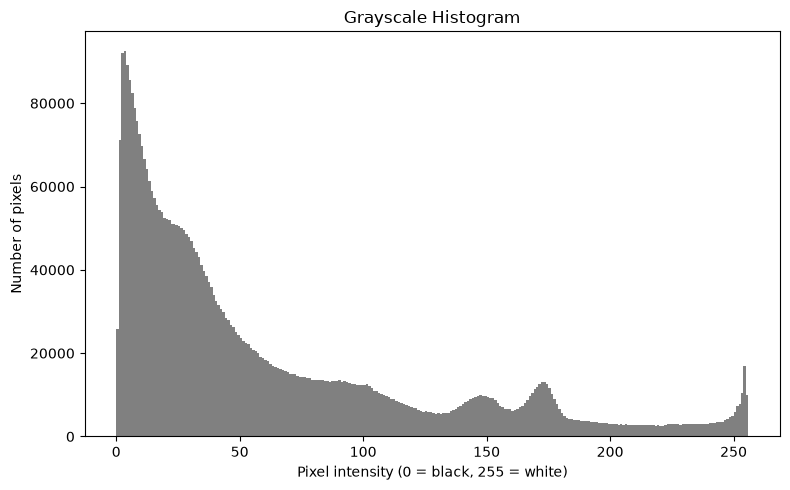

Mean intensity          : 61.7
Dark pixels   (0-84)    : 73.1%
Mid pixels    (85-169)  : 17.7%
Bright pixels (170-255) : 9.2%


In [6]:
flat = gray.flatten()
print("Flattened grayscale size:", flat.size)

fig = plt.figure(figsize=(8, 5))
plt.hist(flat, bins=256, range=(0, 256), color="gray")
plt.title("Grayscale Histogram")
plt.xlabel("Pixel intensity (0 = black, 255 = white)")
plt.ylabel("Number of pixels")
plt.tight_layout()
fig.savefig("grayscale_histogram.png", dpi=120)
plt.show()

# Numbers to support your written interpretation
print(f"Mean intensity          : {flat.mean():.1f}")
print(f"Dark pixels   (0-84)    : {np.mean(flat < 85) * 100:.1f}%")
print(f"Mid pixels    (85-169)  : {np.mean((flat >= 85) & (flat < 170)) * 100:.1f}%")
print(f"Bright pixels (170-255) : {np.mean(flat >= 170) * 100:.1f}%")

**Histogram interpretation:** The image is **mainly dark**. The mean intensity is 61.7 out of 255, and 73.1% of the pixels fall in the dark range (0-84), compared with 17.7% mid-tones (85-169) and only 9.2% bright pixels (170-255). The tall peak near 0-10 comes from the night sky, shadows, and asphalt, while the small bumps around 150-175 and the spike at 255 come from the yellow car and the bright neon signs and street lights.

**What a histogram shows and does not show:** A histogram shows how many pixels have each intensity value, so it reveals overall brightness, contrast, and whether highlights or shadows are clipped. It does **not** show where the pixels are located (spatial arrangement), what objects are in the image, or color information, because two very different images can have the same histogram.

## Step 7: Demonstrate Bit Depth

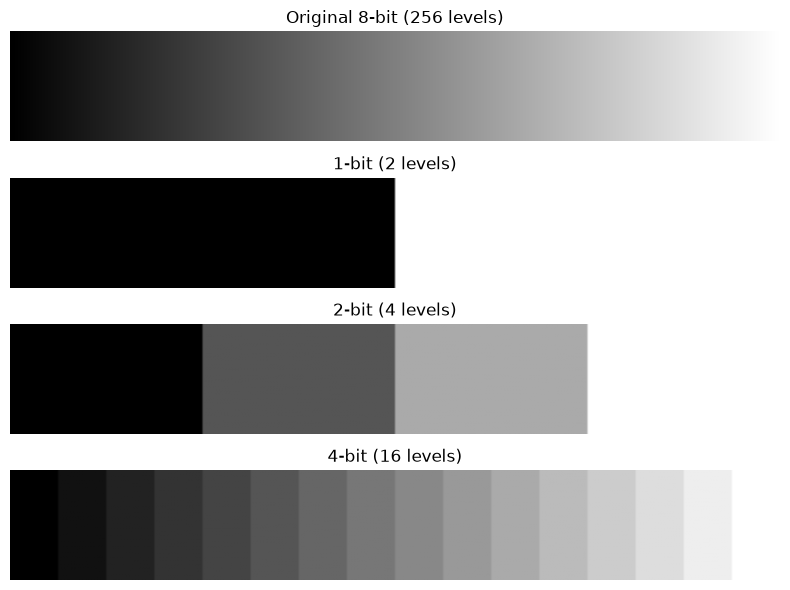

Unique values in 8-bit gradient : 256
Unique values in 1-bit gradient : 2
Unique values in 2-bit gradient : 4
Unique values in 4-bit gradient : 16


In [7]:
# 8-bit horizontal gradient 0..255 (256 wide, 80 tall)
gradient = np.tile(np.arange(256, dtype=np.uint8), (80, 1))

def quantize(img, bits):
    """Reduce to 2**bits intensity levels, spread over 0..255."""
    levels = 2 ** bits
    step = 256 // levels
    scale = 255 // (levels - 1)
    return ((img // step) * scale).astype(np.uint8)

q1, q2, q4 = quantize(gradient, 1), quantize(gradient, 2), quantize(gradient, 4)
versions = [
    (gradient, "Original 8-bit (256 levels)"),
    (q1, "1-bit (2 levels)"),
    (q2, "2-bit (4 levels)"),
    (q4, "4-bit (16 levels)"),
]

fig, axes = plt.subplots(4, 1, figsize=(8, 6))
for ax, (img, title) in zip(axes, versions):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
fig.savefig("evidence/bit_depth_figure.png", dpi=120)
plt.show()

print("Unique values in 8-bit gradient :", len(np.unique(gradient)))
print("Unique values in 1-bit gradient :", len(np.unique(q1)))
print("Unique values in 2-bit gradient :", len(np.unique(q2)))
print("Unique values in 4-bit gradient :", len(np.unique(q4)))

**Resolution vs bit depth:** Resolution is the number of pixels in the image (width x height, e.g. 2400 x 1792), so it controls how much spatial detail the image can hold. Bit depth is the number of bits used to store each pixel's intensity, so it controls how many different brightness (or color) levels each pixel can take: 1 bit gives 2 levels, 2 bits give 4, 4 bits give 16, and 8 bits give 256. Lowering resolution makes the image blocky or smaller, while lowering bit depth makes smooth gradients break into visible bands, as the figure above shows.

## Step 8: Final Check
This cell confirms that all required output files exist and are valid.

In [8]:
import os

required = ["photo.jpg", "resized_crop.png", "grayscale_histogram.png", ".gitignore"]
for name in required:
    print(f"{name:<26} exists:", os.path.isfile(name))

check = cv.imread("resized_crop.png")
print("resized_crop.png shape     :", None if check is None else check.shape)
print("resized_crop.png is 200x200:", check is not None and check.shape[:2] == (200, 200))
print("All required files present :", all(os.path.isfile(n) for n in required))

photo.jpg                  exists: True
resized_crop.png           exists: True
grayscale_histogram.png    exists: True
.gitignore                 exists: True
resized_crop.png shape     : (200, 200, 3)
resized_crop.png is 200x200: True
All required files present : True
